Q1

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Words: ['sports', 'play', 'an', 'important', 'role', 'in', 'our', 'daily', 'lives', 'players', 'practice', 'regularly', 'to', 'improve', 'their', 'performance', 'young', 'people', 'enjoy', 'watching', 'and', 'playing', 'different', 'games', 'regular', 'exercise', 'helps', 'people', 'stay', 'fit', 'and', 'healthy', 'athletes', 'learn', 'discipline', 'and', 'teamwork', 'through', 'sports', 'playing', 'games', 'makes', 'our', 'lives', 'more', 'active', 'and', 'enjoyable']
Sentences: ['sports play an important role in our daily lives.', 'players practice regularly to improve their performance.', 'young people enjoy watching and playing different games.', 'regular exercise helps people stay fit and healthy.', 'athletes learn discipline and teamwork through sports.', 'playing games makes our lives more active and enjoyable.']
Using split(): ['sports', 'play', 'an', 'important', 'role', 'in', 'our', 'daily', 'lives', 'players', 'practice', 'regularly', 'to', 'improve', 'their', 'performance',

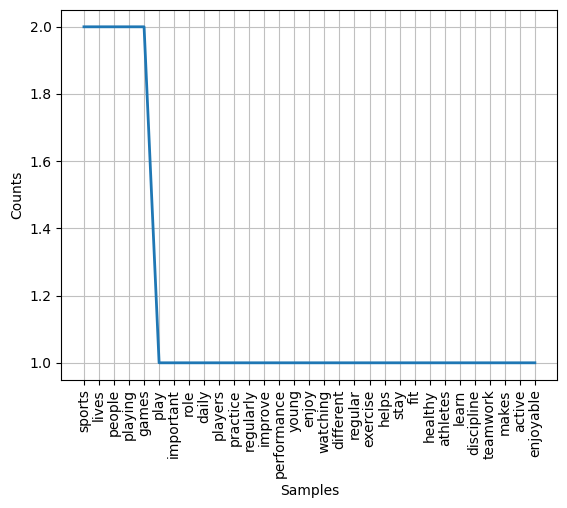

In [1]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

original_text = """Sports play an important role in our daily lives.
Players practice regularly to improve their performance.
Young people enjoy watching and playing different games.
Regular exercise helps people stay fit and healthy.
Athletes learn discipline and teamwork through sports.
Playing games makes our lives more active and enjoyable."""

text = original_text.lower()
text = re.sub(r'[^\w\s]', '', text)

words = word_tokenize(text)
sentences = sent_tokenize(original_text.lower())

print("Words:", words)
print("Sentences:", sentences)

print("Using split():", text.split())
print("Using word_tokenize():", word_tokenize(text))
# split() only breaks on whitespace, so punctuation stays attached to words ("rapidly." stays as one token).
# word_tokenize() separates punctuation into its own tokens and handles contractions ("don't" becomes "do" and "n't").

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("After removing stopwords:", filtered_words)

fdist = FreqDist(filtered_words)
print("Word frequency:", fdist)
print("Frequency list:", fdist.most_common())

fdist.plot()
plt.show()

Q2

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

words = re.findall(r'\b[a-zA-Z]+\b', text)

print("Words containing only alphabets:", words)

stop_words = set(stopwords.words('english'))
filtered_words = []

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("After removing stopwords:", filtered_words)

ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = []
lemmatized_words = []

for word in filtered_words:
    stemmed_words.append(ps.stem(word))
    lemmatized_words.append(lemmatizer.lemmatize(word))

print("Stemmed words:", stemmed_words)
print("Lemmatized words:", lemmatized_words)

# Stemming chops suffixes by rules and can produce non-words, as in your output ("artifici", "intellig", "rapidli", "everi").
# Lemmatization uses a dictionary and returns real words ("life", "people", "computer").
# Prefer stemming when speed matters and exact words don't, as in search or indexing.
# Prefer lemmatization when the output must be real words with correct meaning, as in chatbots and text analysis.

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Words containing only alphabets: ['sports', 'play', 'an', 'important', 'role', 'in', 'our', 'daily', 'lives', 'players', 'practice', 'regularly', 'to', 'improve', 'their', 'performance', 'young', 'people', 'enjoy', 'watching', 'and', 'playing', 'different', 'games', 'regular', 'exercise', 'helps', 'people', 'stay', 'fit', 'and', 'healthy', 'athletes', 'learn', 'discipline', 'and', 'teamwork', 'through', 'sports', 'playing', 'games', 'makes', 'our', 'lives', 'more', 'active', 'and', 'enjoyable']
After removing stopwords: ['sports', 'play', 'important', 'role', 'daily', 'lives', 'players', 'practice', 'regularly', 'improve', 'performance', 'young', 'people', 'enjoy', 'watching', 'playing', 'different', 'games', 'regular', 'exercise', 'helps', 'people', 'stay', 'fit', 'healthy', 'athletes', 'learn', 'discipline', 'teamwork', 'sports', 'playing', 'games', 'makes', 'lives', 'active', 'enjoyable']
Stemmed words: ['sport', 'play', 'import', 'role', 'daili', 'live', 'player', 'practic', 'regul

Q3

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "TThis smartwatch tracks daily steps and monitors heart rate.",
"The headphones deliver clear sound and have a comfortable design.",
"The laptop runs smoothly and handles everyday tasks well."
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words:")
print(cv.get_feature_names_out())
print(bow.toarray())

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)

words = tfidf.get_feature_names_out()
scores = tfidf_matrix.toarray()

print("\nTF-IDF Scores:")
print(words)
print(scores)

print("\nTop 3 keywords from each text:")

for i in range(len(texts)):
    word_scores = list(zip(words, scores[i]))
    word_scores.sort(key=lambda x: x[1], reverse=True)

    print("\nText", i + 1, ":", texts[i])
    for word, score in word_scores[:3]:
        print(word, ":", round(score, 3))
# A high TF-IDF score means the word appears in that text but is rare in the others.
# Words shared across texts ("good", "battery", "phone") score lower.
# In Text 2, "laptop", "fast" and "processor" are tied at 0.46 and describe it best.

Bag of Words:
['and' 'clear' 'comfortable' 'daily' 'deliver' 'design' 'everyday'
 'handles' 'have' 'headphones' 'heart' 'laptop' 'monitors' 'rate' 'runs'
 'smartwatch' 'smoothly' 'sound' 'steps' 'tasks' 'the' 'tracks' 'tthis'
 'well']
[[1 0 0 1 0 0 0 0 0 0 1 0 1 1 0 1 0 0 1 0 0 1 1 0]
 [1 1 1 0 1 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0]
 [1 0 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 1]]

TF-IDF Scores:
['clear' 'comfortable' 'daily' 'deliver' 'design' 'everyday' 'handles'
 'headphones' 'heart' 'laptop' 'monitors' 'rate' 'runs' 'smartwatch'
 'smoothly' 'sound' 'steps' 'tasks' 'tracks' 'tthis']
[[0.         0.         0.35355339 0.         0.         0.
  0.         0.         0.35355339 0.         0.35355339 0.35355339
  0.         0.35355339 0.         0.         0.35355339 0.
  0.35355339 0.35355339]
 [0.40824829 0.40824829 0.         0.40824829 0.40824829 0.
  0.         0.40824829 0.         0.         0.         0.
  0.         0.         0.         0.40824829 0.         0.
  0.    

Q4

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')

text1 = """Blockchain stores information in secure digital records.
It helps users share data without a central authority.
It is used in finance, healthcare and supply chains.
Cryptography helps protect blockchain transactions."""

text2 = """Renewable energy comes from natural sources like sunlight and wind.
It helps reduce pollution and protect the environment.
Solar panels are used to produce clean electricity.
Renewable energy is becoming more popular around the world."""

stop_words = set(stopwords.words('english'))

words1 = re.findall(r'\b[a-zA-Z]+\b', text1.lower())
words2 = re.findall(r'\b[a-zA-Z]+\b', text2.lower())

words1 = [word for word in words1 if word not in stop_words]
words2 = [word for word in words2 if word not in stop_words]

print("Text 1 tokens:", words1)
print("Text 2 tokens:", words2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("Jaccard Similarity:", jaccard)

texts = [text1, text2]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])

print("Cosine Similarity:", cosine[0][0])
# Jaccard only counts shared unique words and ignores how often they appear.
# Cosine on TF-IDF weights words by importance. Here both are low (about 0.08), which correctly shows the two topics are different.
# Cosine is usually better because it accounts for word weights.

Text 1 tokens: ['blockchain', 'stores', 'information', 'secure', 'digital', 'records', 'helps', 'users', 'share', 'data', 'without', 'central', 'authority', 'used', 'finance', 'healthcare', 'supply', 'chains', 'cryptography', 'helps', 'protect', 'blockchain', 'transactions']
Text 2 tokens: ['renewable', 'energy', 'comes', 'natural', 'sources', 'like', 'sunlight', 'wind', 'helps', 'reduce', 'pollution', 'protect', 'environment', 'solar', 'panels', 'used', 'produce', 'clean', 'electricity', 'renewable', 'energy', 'becoming', 'popular', 'around', 'world']
Jaccard Similarity: 0.07317073170731707
Cosine Similarity: 0.08351663291672917


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Q5

Review: This laptop is impressive and the screen quality is excellent.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: The application is very useful and easy to navigate.
Polarity: 0.4116666666666667
Subjectivity: 0.4166666666666667
Sentiment: Positive

Review: I am satisfied with the sound quality and speed.
Polarity: 0.45
Subjectivity: 0.7
Sentiment: Positive

Review: The service is terrible and the customer support is poor.
Polarity: -0.7
Subjectivity: 0.8
Sentiment: Negative

Review: I am unhappy with this purchase.
Polarity: -0.6
Subjectivity: 0.9
Sentiment: Negative

Review: The experience is neither good nor bad.
Polarity: 5.551115123125783e-17
Subjectivity: 0.6333333333333333
Sentiment: Neutral



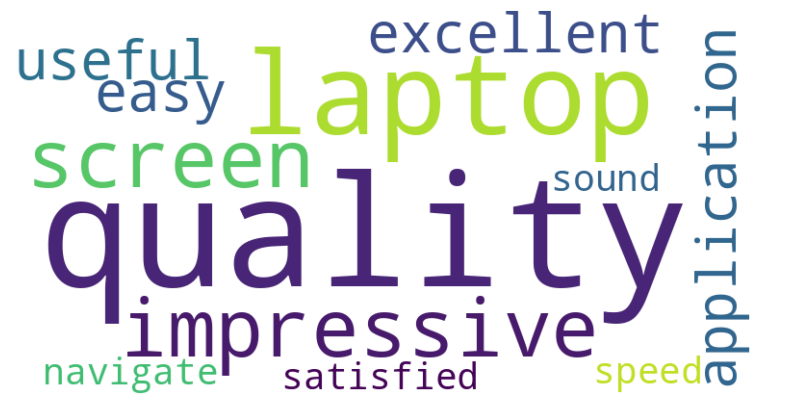

In [5]:
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This laptop is impressive and the screen quality is excellent.",
    "The application is very useful and easy to navigate.",
    "I am satisfied with the sound quality and speed.",
    "The service is terrible and the customer support is poor.",
    "I am unhappy with this purchase.",
    "The experience is neither good nor bad."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)
    print()

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(width=800, height=400, background_color="white")
wordcloud.generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Q6

In [6]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """basketball is a popular sport around the world
players practice every day to improve their performance
a team has five players on the court
the goalkeeper protects the goal from the opposing team
players pass the ball to score points
good teamwork helps players win games
coaches train players and develop strategies
fans support their favorite team during every match
the referee makes decisions and ensures fair play
basketball teaches teamwork and discipline"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

sequences = []
for line in text.split("\n"):
    numbers = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(numbers) + 1):
        sequences.append(numbers[:i])

max_length = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_length)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential()
model.add(Embedding(total_words, 16))
model.add(LSTM(64))
model.add(Dense(total_words, activation="softmax"))

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam")

model.fit(X, y, epochs=200, verbose=0)

def generate_text(seed, num_words):
    text_so_far = seed
    for _ in range(num_words):
        numbers = tokenizer.texts_to_sequences([text_so_far])[0]
        numbers = pad_sequences([numbers], maxlen=max_length - 1)
        prediction = model.predict(numbers, verbose=0)
        next_index = np.argmax(prediction)
        text_so_far = text_so_far + " " + tokenizer.index_word[next_index]
    return text_so_far

print(generate_text("football", 4))
print(generate_text("players", 4))
print(generate_text("the", 4))

football teaches teamwork and discipline
players pass the ball to
the referee makes decisions and
